In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.append(os.path.abspath('..'))
from classes import Document
from data_representations import build_profiling_features
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.dummy import DummyClassifier

In [2]:
# caricamento e lettura del dizionario json contenente i metadati
with open('../dataset/document_info.json', 'r') as f:
    doc_info = json.load(f)

In [3]:
conllu_path = '../profiling_output' # cartella dove sono salvati i file .conllu (aventi annotazioni linguistiche)
all_documents = []
for doc_id, info in doc_info.items(): # iterazione su ogni elemento del dizionario json dove doc_id è la chiave e info contiene il dizionario con 'label' e 'split'
    path = os.path.join(conllu_path, f"{doc_id}.conllu") # costruzione del percorso completo per ogni elemento del dict, unendo la cartella (profiling_output), l'ID del documento e l'estensione .conllu
    doc = Document(path, doc_id, info['split'], info['label']) # istanza della classe Document che permette di estrarre info su 'label' e 'split'
    doc.load_sentences_from_conllu() # l'algoritmo di parsing popola l'istanza doc con tutte le annotazioni linguistiche necessarie rendendo i dati strutturati
    all_documents.append(doc)

# suddivisione dei documenti appena popolati di info linguistiche in base al loro 'split' (set di appartenenza)
train_docs = [d for d in all_documents if d.split == 'training']
val_docs = [d for d in all_documents if d.split == 'validation']
test_docs = [d for d in all_documents if d.split =='test']

# estrazione delle etichette e conversione in array NumPy (necessarie per addestramento e valutazione del modello)
y_train = np.array([d.label for d in train_docs])
y_val = np.array([d.label for d in val_docs])
y_test = np.array([d.label for d in test_docs])

# check delle dimensioni dei subsets 
print(f'Dimensione dataset intero: {len(all_documents)}')
print(f'Dimensione training set: {len(train_docs)}, train labels: {len(y_train)}')
print(f'Dimensione validation set: {len(val_docs)}, validation labels: {len(y_val)}')
print(f'Dimensione test set: {len(test_docs)}, test labels: {len(y_test)}')

Dimensione dataset intero: 4000
Dimensione training set: 2000, train labels: 2000
Dimensione validation set: 1000, validation labels: 1000
Dimensione test set: 1000, test labels: 1000


In [4]:
csv_profiling_path = "linguistic_profiling.csv"
X_train_cv, _, features_names = build_profiling_features(
        train_docs, # per il training del modello finale 
        val_docs, # è val_docs al primo giro e test_docs al secondo 
        csv_profiling_path
    )

# scaling delle features in modo che abbiano media 0 e varianza 1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_cv) # il metodo fit consente allo scaler di apprendere il valore massimo assoluto (parametro) per ogni colonna della matrice 

model = LinearSVC(dual=False, random_state = 26, max_iter=5000) # definizione della SVM lineare 
scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='f1_macro') # esecuzione della k-fold cv solo su training set e restituisce un array con i 5 punteggi di F1 (macro) ottenuti 


==================== ANALISI FOLD-BY-FOLD: VALIDATION SET ====================
F1 score fold 1: 0.92, baseline: 0.32
F1 score fold 2: 0.91, baseline: 0.33
F1 score fold 3: 0.91, baseline: 0.33
F1 score fold 4: 0.88, baseline: 0.30
F1 score fold 5: 0.93, baseline: 0.29

Overall f1: 0.91

VALUTAZIONE FINALE: VALIDATION SET
Baseline F1 (macro) score (VALIDATION SET): 0.3333

REPORT BASELINE (DUMMY):
              precision    recall  f1-score   support

       Human       0.50      1.00      0.67       500
          AI       0.00      0.00      0.00       500

    accuracy                           0.50      1000
   macro avg       0.25      0.50      0.33      1000
weighted avg       0.25      0.50      0.33      1000


REPORT MODELLO SVM:
              precision    recall  f1-score   support

       Human       0.94      0.94      0.94       500
          AI       0.94      0.94      0.94       500

    accuracy                           0.94      1000
   macro avg       0.94      0.94

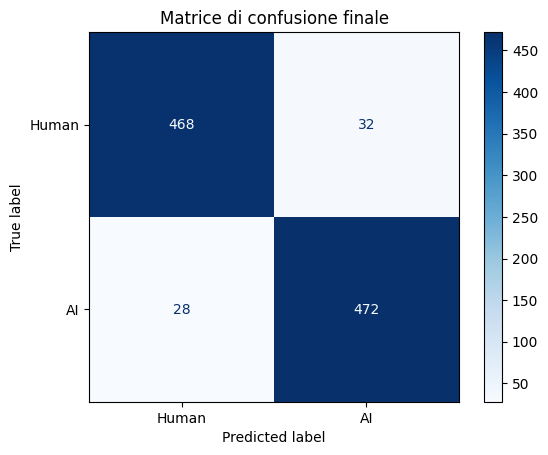


==================== ANALISI FOLD-BY-FOLD: TEST SET ====================
F1 score fold 1: 0.91, baseline: 0.32
F1 score fold 2: 0.86, baseline: 0.33
F1 score fold 3: 0.90, baseline: 0.33
F1 score fold 4: 0.84, baseline: 0.30
F1 score fold 5: 0.91, baseline: 0.29

Overall f1: 0.89

VALUTAZIONE FINALE: TEST SET
Baseline F1 (macro) score (TEST SET): 0.3333

REPORT BASELINE (DUMMY):
              precision    recall  f1-score   support

       Human       0.50      1.00      0.67       500
          AI       0.00      0.00      0.00       500

    accuracy                           0.50      1000
   macro avg       0.25      0.50      0.33      1000
weighted avg       0.25      0.50      0.33      1000


REPORT MODELLO SVM:
              precision    recall  f1-score   support

       Human       0.83      0.94      0.88       500
          AI       0.94      0.81      0.87       500

    accuracy                           0.88      1000
   macro avg       0.88      0.88      0.88      10

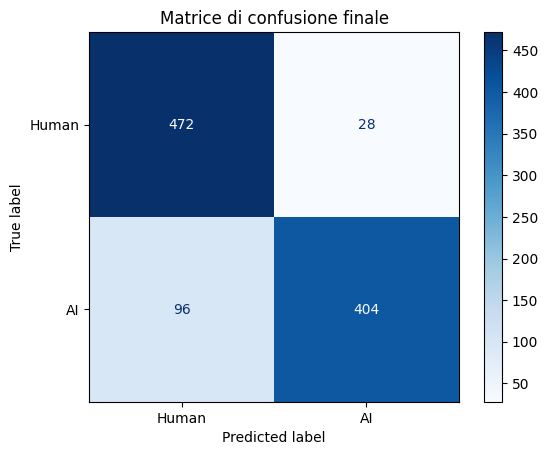

In [5]:
# creazione di un dict che raccoglie i sets su cui si vuole testare il modello finale individuato nella fase di cross validation
evaluation_targets = [
    (val_docs, y_val, "VALIDATION SET"),
    (test_docs, y_test, "TEST SET")
]

# creazione di un dict vuoto in cui verranno successivamente salvati i risultati del test set per l'analisi qualitativa
qualitative_results = {}

# inizializzazione di un ciclo per processare i due set di valutazione separatamente 
for docs, labels, name in evaluation_targets:
    # la funzione build_profiling_features fa il mapping dal nome del file al doc_id e crea la matrice delle features 
    X_train_final, X_eval_final, features_names = build_profiling_features(
        train_docs, # per il training del modello finale 
        docs, # è val_docs al primo giro e test_docs al secondo 
        csv_profiling_path
    )
    
    scaler = StandardScaler()
    X_train_final_scaled = scaler.fit_transform(X_train_final)
    X_eval_final_scaled = scaler.transform(X_eval_final) # non viene applicato il metodo fit perché è il set su cui il modello deve fare predizioni
    
    baseline = DummyClassifier(strategy="most_frequent") # modello che sceglie la classe più frequente per fare le sue predizioni
    baseline.fit(X_train_final_scaled, y_train) # fit per apprendimento della classe più frequente (y)
    baseline_preds = baseline.predict(X_eval_final_scaled)
    baseline_score = f1_score(labels, baseline_preds, average='macro')
    
    # addestramento del modello finale con la configurazione vincitrice 
    final_model = LinearSVC(dual = False, random_state=26, max_iter=5000)
    final_model.fit(X_train_final_scaled, y_train)
    y_pred = final_model.predict(X_eval_final_scaled)
    
    print(f"\n{'='*20} ANALISI FOLD-BY-FOLD: {name} {'='*20}")
    # split del dataset in 5 folds 
    splitter = KFold(n_splits=5, random_state=26, shuffle=True)
    
    # inizializzazione delle liste per accumulare le etichette reali e le predizioni utili per il calcolo dell'F1 complessivo
    all_y_true = []
    all_y_pred = []

    for i, (train_ids, test_ids) in enumerate(splitter.split(X_eval_final_scaled)): #splitter.split fornisce gli indici per dividere i dati (4 folds per il training e 1 per il test)
        fold_X_train = X_eval_final_scaled[train_ids]
        fold_y_train = labels[train_ids]
        fold_X_test = X_eval_final_scaled[test_ids]
        fold_y_test = labels[test_ids]

        final_model.fit(fold_X_train, fold_y_train)
        fold_y_pred = final_model.predict(fold_X_test)

        # calcolo di F1 score per il fold corrente 
        fold_f1 = f1_score(fold_y_test, fold_y_pred, average='macro') 
    
        baseline_fold = DummyClassifier(strategy="most_frequent")
        baseline_fold.fit(fold_X_train, fold_y_train)
        baseline_fold_f1 = f1_score(fold_y_test, baseline_fold.predict(fold_X_test), average='macro') 

        # i risultati ottenuti vengono aggiungi alle liste inizializzate in precedenza
        all_y_true += fold_y_test.tolist() 
        all_y_pred += fold_y_pred.tolist()
        
        print(f"F1 score fold {i+1}: {fold_f1:.2f}, baseline: {baseline_fold_f1:.2f}") # 

    overall_f1 = f1_score(all_y_true, all_y_pred, average='macro') 
    print(f"\nOverall f1: {overall_f1:.2f}")
    
    # valutazione delle prestazioni del modello vincitore sul set corrente 
    cv_scores = cross_val_score(final_model, X_eval_final_scaled, labels, cv=5, scoring='f1_macro')
    
    # la decision function calcola la distanza di ogni documento dal confine di decisione --> più il modello è lontano da 0, più il modello è sicuro della sua scelta 
    scores = final_model.decision_function(X_eval_final_scaled)

    # se il ciclo fro sta processando il test set (vedi evaluation_targets) i risultati vengono salvati per l'analisi linguistica 
    if name == "TEST SET":
        qualitative_results = {'docs': docs, 'labels': labels, 'preds': y_pred, 'scores': scores} 

    print(f"\n" + "="*50)
    print(f"VALUTAZIONE FINALE: {name}")
    print(f"="*50)
    print(f"Baseline F1 (macro) score ({name}): {baseline_score:.4f}")
    
    print(f"\nREPORT BASELINE (DUMMY):")
    print(classification_report(labels, baseline_preds, target_names=['Human', 'AI'], zero_division=0))
    
    print(f"\nREPORT MODELLO SVM:")
    print(classification_report(labels, y_pred, target_names=['Human', 'AI']))
    
    print(f"Score della decision function (primi 5): {np.round(scores[:5], 3)}")

    cm = confusion_matrix(labels, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Human', 'AI'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title("Matrice di confusione finale")
    plt.show()

docs_test = qualitative_results['docs']
labels_test = qualitative_results['labels']
scores_test = qualitative_results['scores']

In [6]:
# identificazione dei casi incerti trasformando dapprima tutti gli scores in valori positivi (np.abs) e confrontando se sia < 0.5 
# lo score a 0.5 individua testi molto vicini all'iperpiano, segnalando l'incertezza del modello 
abs_scores = np.abs(scores_test)
uncertain_idx = np.argsort(abs_scores)[:5]

print(f"\nANALISI DEI CASI INCERTI (distanza dall'iperpiano < 0.5):")
for i in uncertain_idx: # si stampano solo i primi 5 casi incerti 
    print(f"\nID documento: {docs_test[i].doc_id}")
    print(f"Etichetta reale: {labels_test[i]} | Predizione: {qualitative_results['preds'][i]} | Score: {scores_test[i]:.4f}")
    extracted_text = ''.join([s.text for s in docs_test[i].sentences[:3]])
    print(f"Testo: {extracted_text}")


ANALISI DEI CASI INCERTI (distanza dall'iperpiano < 0.5):

ID documento: test_7165
Etichetta reale: 1 | Predizione: 0 | Score: -0.0051
Testo: 1.**Margherita Buy:** con un cachet di 400 mila euro per puntata, l'attrice romana è la più pagata della televisione italiana.2.

ID documento: test_13036
Etichetta reale: 1 | Predizione: 0 | Score: -0.0073
Testo: Ieri sera gli ultimi due terroristi rimasti legati a Salah Abdeslam si sono recati in auto allo Stade, forse evidentemente seguendo il segnale del telefono che li avrebbe localizzati dalla polizia.Dopo un primo conflitto a fuoco, la polizia ha fatto irruzione nello Stade con il supporto di unità specializzate in esplosivi e artificieri.Probabilmente a uccidere Abaaoud e mentre era confinato in un locale sul retro degli spalti dello Stade dove si era arroccato in un bunker telefonico protetto da poliziotti francesi arrivati dopo lo sgombero dei tifosi è stato un breve conflitto a fuoco in cui uno dei terroristi è stato ucciso e l'altro 

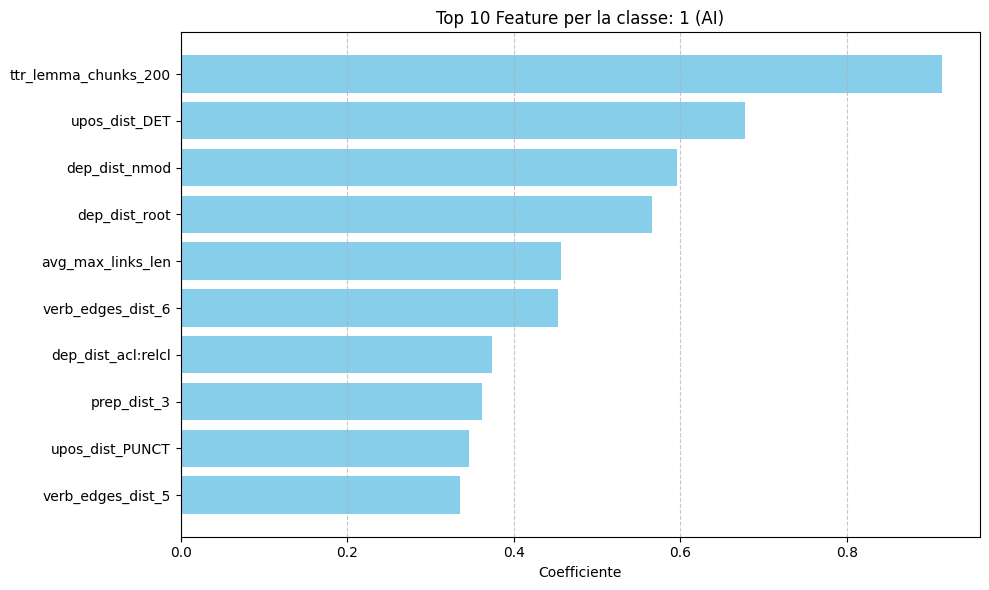

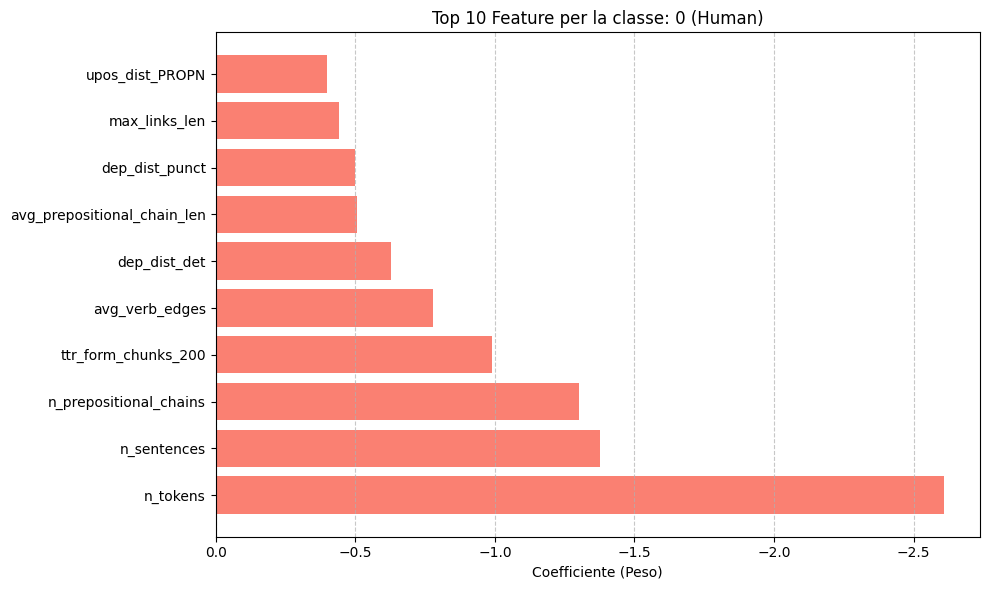

In [7]:
# estrazione dei pesi dal modello finale tramite coef_[0] che contiene i coefficienti (pesi) assegnati dalla SVM a ogni feature
# un peso alto positivo spinge verso la classe 1 (AI), altrimenti verso la classe 0 (human)
coefficients = final_model.coef_[0]
feature_names = np.array(features_names)

num_features = 10 # selezione di 10 features campione (10 con indice positivo + 10 con indice negativo)
top_positive_indices = np.argsort(coefficients)[-num_features:] # i pesi vengono posizionati in ordine crescente e si selezionano gli ultimi 10 (i più grandi positivi)
top_negative_indices = np.argsort(coefficients)[:num_features] # si selezionano i primi 10 pesi (i più grandi negativi)

plt.figure(figsize=(10,6))
plt.barh(range(num_features), coefficients[top_positive_indices], color='skyblue')
plt.yticks(range(num_features), feature_names[top_positive_indices])
plt.xlabel('Coefficiente')
plt.title(f'Top {num_features} Feature per la classe: {final_model.classes_[1]} (AI)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.barh(range(num_features), coefficients[top_negative_indices], color='salmon')
plt.yticks(range(num_features), feature_names[top_negative_indices])
plt.xlabel('Coefficiente (Peso)')
plt.title(f'Top {num_features} Feature per la classe: {final_model.classes_[0]} (Human)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_xaxis() 
plt.tight_layout()
plt.show()